# SQL und Python im Jupyter Notebook

Lern-Notebook zur Roadmap `Roadmap_SQL_Python_Jupyter.md`: PostgreSQL-Daten aus Python heraus abfragen, auswerten, darstellen und verändern. Übungsdatenbank ist **Pagila** (Videoverleih: Filme, Kunden, Ausleihen, Zahlungen).

Das Notebook ist zugleich die **History** des Lernwegs: Jede Phase steht so im Notebook, wie sie bearbeitet wurde, und bleibt lauffähig. Neuer, wiederverwendbarer Code liegt ab Phase 9 im Modul `database.py`.

**Inhalt**

| Phase | Thema |
|---|---|
| 0 | Umgebung und Verbindung |
| 1 | SQL direkt im Notebook (JupySQL) |
| 2 | Datenbankzugriff mit psycopg |
| 3 | Auswerten mit pandas |
| 4 | SQLAlchemy Core |
| 5 | Darstellen mit matplotlib |
| 6 | Daten schreiben und Transaktionen |
| 7 | CSV laden und bereinigen |
| 8 | Performance und Indizes |
| 9 | Vom Notebook zum Modul, Tests mit pytest |
| 10 | Abschlussprojekt: Umsatz nach Filmkategorien |

**Voraussetzungen zum Ausführen**

- PostgreSQL läuft lokal mit der Datenbank `pagila`, Nutzer `accsess_pagila` mit dem Recht, Schemas anzulegen.
- Kernel aus der `.venv` des Projektordners.
- Das Notebook läuft mit **Restart & Run All** von oben nach unten durch. Dabei werden die Übungstabellen im Schema `own` neu erzeugt (u. a. 2 Millionen Zeilen in Phase 8, ca. 15 Sekunden).

> Die Zugangsdaten stehen bewusst direkt im Code, weil es sich nur um eine lokale Testdatenbank handelt.

## Phase 0 – Umgebung und Verbindung

Alle Pakete werden direkt im Notebook installiert. `%pip` installiert immer in das Python des laufenden Kernels (hier die `.venv`). Nach einer Neuinstallation muss der Kernel einmal neu gestartet werden.

In [1]:
%pip install "sqlalchemy>=2.0,<2.1"
%pip install "psycopg[binary]"
%pip install "pandas"
%pip install "matplotlib"
%pip install "pytest"

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


### Imports und Konfiguration

Diese Zelle gilt für das ganze Notebook:

- **Imports** aller Bibliotheken, die in mehreren Phasen gebraucht werden. `matplotlib.pyplot` heißt hier `plotter`.
- **JupySQL** (`%load_ext sql`) für die `%sql`- und `%%sql`-Zellen. `displaycon` und `feedback` blenden die Meldungen „Running query in …“ und „x rows affected“ aus, `displaylimit` zeigt bis zu 30 Ergebniszeilen an (wichtig für vollständige Pläne in Phase 8).
- **autoreload**: Änderungen an `database.py` werden ohne Kernel-Neustart übernommen (Phase 9).
- **Verbindungsdaten** zu Pagila.

In [2]:
# --- Imports ----------------------------------------------------------
import sys

import matplotlib.pyplot as plotter
import pandas
import sqlalchemy

import database

# --- Jupyter-Erweiterungen --------------------------------------------
%load_ext sql
%load_ext autoreload
%autoreload 2

%config SqlMagic.displaycon = False
%config SqlMagic.feedback = 0
%config SqlMagic.displaylimit = 30

# --- Verbindungsdaten Pagila ------------------------------------------
pagila_db_name = "pagila"
pagila_host = "localhost"
pagila_port = "5432"
pagila_user = "accsess_pagila"
pagila_password = "pagila_password"
pagila_url = f"postgresql+psycopg://{pagila_user}:{pagila_password}@{pagila_host}:{pagila_port}/{pagila_db_name}"

### Verbindung herstellen

`create_engine` erzeugt die SQLAlchemy-**Engine** `pagila`. Sie wird im ganzen Notebook geteilt: von `pandas.read_sql`, von eigenen Funktionen und von JupySQL (`%sql pagila`).

In [3]:
pagila = sqlalchemy.create_engine(pagila_url)
%sql pagila

### Verbindungstest

Die erste Abfrage zeigt, dass Verbindung und Pagila-Daten funktionieren.

In [4]:
%%sql
SELECT
    film.film_id,
    film.title,
    film.release_year
FROM film
LIMIT 5

film_id,title,release_year
483,JERICHO MULAN,2016
310,FEVER EMPIRE,2017
349,GANGS PRIDE,2012
475,JAPANESE RUN,2009
1,ACADEMY DINOSAUR,2012


## Phase 1 – SQL direkt im Notebook (JupySQL)

**Ziel:** SQL in Zellen schreiben und das Ergebnis in Python weiterverwenden.

> Eigene Notiz: Das Schwierigste an Phase 0 und 1 war die Verbindung zur Datenbank.

### Filme einer Kategorie

`{{category_name}}` setzt den Wert einer Python-Variable in die Abfrage ein. Mit `%%sql name <<` wird das Ergebnis in der Variable `name` gespeichert.

In [5]:
category_name = "Action"

In [6]:
%%sql action_films_result <<
SELECT
    film.title,
    film.release_year
FROM film
JOIN film_category ON film_category.film_id = film.film_id
JOIN category ON category.category_id = film_category.category_id
WHERE category.name = '{{category_name}}'
ORDER BY film.title

`.DataFrame()` wandelt das JupySQL-Ergebnis in einen pandas-DataFrame um.

In [7]:
action_films = action_films_result.DataFrame()

In [8]:
print(action_films.head())
print(len(action_films))

              title  release_year
0    ACE GOLDFINGER          2023
1  ADAPTATION HOLES          2017
2   AIRPLANE SIERRA          2019
3    ALASKA PHANTOM          2016
4       ANGELS LIFE          2009
149


### Dieselbe Abfrage als Funktion

`%%sql` muss die erste Zeile einer Zelle sein und lässt sich deshalb nicht in eine Funktion packen. Stattdessen nutzt die Funktion die Engine direkt:

- `sqlalchemy.text(...)` mit dem **benannten Parameter** `:category_name`
- `pandas.read_sql(..., params=...)` liefert direkt einen DataFrame

Anders als `{{...}}` wird der Wert dabei getrennt an PostgreSQL geschickt und nie als SQL ausgeführt (Schutz vor SQL-Injection).

In [9]:
def get_films_by_category(category_name):
    """
    Liefert alle Filme einer Kategorie (Titel und Erscheinungsjahr) als DataFrame.

    Parameter:
        category_name -- Name der Kategorie, z. B. "Action"
    """
    query = sqlalchemy.text("""
        SELECT
            film.title,
            film.release_year
        FROM film
        JOIN film_category ON film_category.film_id = film.film_id
        JOIN category ON category.category_id = film_category.category_id
        WHERE category.name = :category_name
        ORDER BY film.title
    """)
    return pandas.read_sql(query, pagila, params={"category_name": category_name})

In [10]:
print(get_films_by_category("Action"))

                    title  release_year
0          ACE GOLDFINGER          2023
1        ADAPTATION HOLES          2017
2         AIRPLANE SIERRA          2019
3          ALASKA PHANTOM          2016
4             ANGELS LIFE          2009
..                    ...           ...
144      WEEKEND PERSONAL          2023
145       WHISPERER GIANT          2021
146          WOMEN DORADO          2014
147  WONDERLAND CHRISTMAS          2006
148          ZHIVAGO CORE          2012

[149 rows x 2 columns]


### Kunden mit den meisten Ausleihen

Gruppiert wird nach `customer_id`, nicht nur nach dem Namen: Zwei verschiedene Kunden können gleich heißen und würden sonst zusammengezählt.

In [11]:
def get_top_customers_by_rentals(customer_count):
    """
    Liefert die Kunden mit den meisten Ausleihen, absteigend sortiert.

    Parameter:
        customer_count -- Anzahl der Kunden im Ergebnis (LIMIT)

    Rückgabe:
        DataFrame mit den Spalten name, surname, lends (Anzahl Ausleihen)
    """
    query = sqlalchemy.text("""
        SELECT
            customer.first_name AS name,
            customer.last_name AS surname,
            count(rental.rental_id) AS lends
        FROM customer
        JOIN rental ON rental.customer_id = customer.customer_id
        GROUP BY
            customer.customer_id,
            customer.last_name,
            customer.first_name
        ORDER BY lends DESC
        LIMIT :limit
    """)
    return pandas.read_sql(query, pagila, params={"limit": customer_count})

In [12]:
print(get_top_customers_by_rentals(10))

        name     surname  lends
0    RUSSELL     BRINSON     97
1      LEROY  BUSTAMANTE     95
2        TIM        CARY     94
3     CURTIS        IRBY     91
4        MAX        PITT     90
5     SYLVIA       ORTIZ     89
6      DAISY       BATES     89
7       KARL        SEAL     89
8  ELIZABETH       BROWN     89
9    KRISTIN    JOHNSTON     87


### Umsatz je Filiale und Anteil am Gesamtumsatz

Die fertige View `sales_by_store` liefert den Umsatz pro Filiale. Der Anteil in Prozent wird anschließend in pandas berechnet: Rechnen mit einer ganzen Spalte (Series) wirkt auf jede Zeile, eine Schleife ist nicht nötig.

In [13]:
def get_sales_by_store():
    """Liefert den Umsatz je Filiale aus der View sales_by_store, absteigend sortiert."""
    query = sqlalchemy.text("""
        SELECT *
        FROM sales_by_store
        ORDER BY total_sales DESC
    """)
    return pandas.read_sql(query, pagila)

In [14]:
def get_percentage(part, total):
    """
    Berechnet den Anteil von part an total in Prozent.

    Funktioniert mit einzelnen Zahlen und mit ganzen pandas-Spalten,
    weil nur Rechenzeichen verwendet werden (kein if, keine Schleife).
    """
    return (part / total) * 100

In [15]:
print(get_sales_by_store())

                   store          manager  total_sales
0  Boksburg,South Africa    Warner Hudson     85765.04
1   Hamilton,New Zealand  Lavone O'Reilly     85197.35


In [16]:
store_sales = get_sales_by_store()
total_store_sales = store_sales["total_sales"].sum()
store_sales["percent"] = get_percentage(store_sales["total_sales"], total_store_sales)

In [17]:
print(store_sales)

                   store          manager  total_sales    percent
0  Boksburg,South Africa    Warner Hudson     85765.04  50.166028
1   Hamilton,New Zealand  Lavone O'Reilly     85197.35  49.833972


## Phase 2 – Datenbankzugriff mit psycopg

**Ziel:** Verstehen, was hinter `%sql` und `read_sql` passiert. `psycopg` ist der Treiber, der schon die ganze Zeit unter SQLAlchemy gearbeitet hat (`postgresql+psycopg://...`).

- `psycopg.connect(...)` öffnet die Verbindung, `connection.cursor()` erzeugt den Cursor.
- `execute` schickt die Abfrage, `fetchall` holt die Zeilen ab.
- `with` schließt Verbindung und Cursor auch bei Fehlern.
- `dict_row` liefert jede Zeile als Dictionary statt als Tupel.
- Platzhalter in psycopg: `%(name)s` (nicht `:name` wie bei SQLAlchemy).

In [18]:
import psycopg
from psycopg.rows import dict_row

In [19]:
def get_films_by_category_psycopg(category_name):
    """
    Liefert alle Filme einer Kategorie als Liste von Dictionaries.

    Nutzt psycopg direkt, ohne SQLAlchemy und pandas.

    Parameter:
        category_name -- Name der Kategorie, z. B. "Action"

    Rückgabe:
        Liste wie [{"title": "...", "release_year": 2006}, ...]
    """
    query = """
        SELECT
            film.title,
            film.release_year
        FROM film
        JOIN film_category ON film_category.film_id = film.film_id
        JOIN category ON category.category_id = film_category.category_id
        WHERE category.name = %(category_name)s
        ORDER BY film.title
    """
    with psycopg.connect(host=pagila_host, port=pagila_port, dbname=pagila_db_name,
                         user=pagila_user, password=pagila_password) as connection:
        with connection.cursor(row_factory=dict_row) as cursor:
            cursor.execute(query, {"category_name": category_name})
            return cursor.fetchall()

### Test: SQL-Injection

Abschlusskriterium von Phase 2: Die Eingabe `Action'; --` richtet nichts an. PostgreSQL sucht einfach eine Kategorie mit genau diesem Namen und findet keine (0 Treffer). `Action` liefert dagegen 149 Filme.

In [20]:
print(len(get_films_by_category_psycopg("Action'; --")))
print(len(get_films_by_category_psycopg("Action")))

0
149


### Hilfsfunktionen für psycopg

Kurzformen für Verbindung und Cursor, damit nicht jede Funktion die Verbindungsdaten wiederholt.

In [21]:
def connect_to_pagila():
    """Öffnet eine psycopg-Verbindung zur Pagila-Datenbank."""
    return psycopg.connect(host=pagila_host, port=pagila_port, dbname=pagila_db_name,
                           user=pagila_user, password=pagila_password)

In [22]:
def get_dict_cursor(connection):
    """Erzeugt einen Cursor, der jede Zeile als Dictionary liefert."""
    return connection.cursor(row_factory=dict_row)

## Phase 3 – Auswerten mit pandas

**Ziel:** Entscheiden können, was in SQL und was in pandas gerechnet wird. Dieselbe Auswertung (Umsatz pro Monat) auf zwei Wegen:

1. **Komplett in SQL:** `date_trunc` + `GROUP BY` + `sum`, pandas zeigt nur das Ergebnis.
2. **Rohdaten + pandas:** SQL liefert jede einzelne Zahlung, pandas gruppiert mit `groupby`.

`date_trunc('month', ...)::date` macht aus dem Zeitstempel ein reines Datum. Ohne `::date` würde pandas den Zeitstempel mit Zeitzone nach UTC umrechnen, und jeder Monat erschiene als letzter Tag des Vormonats (z. B. `2021-12-31 23:00` statt `2022-01-01`).

In [23]:
def get_sales_per_month():
    """Umsatz pro Monat, komplett in SQL berechnet (55 Zeilen: month, sales)."""
    query = sqlalchemy.text("""
        SELECT
            date_trunc('month', payment.payment_date)::date AS month,
            sum(payment.amount) AS sales
        FROM payment
        GROUP BY month
        ORDER BY month
    """)
    return pandas.read_sql(query, pagila)

In [24]:
print(get_sales_per_month())

         month     sales
0   2022-01-01   3091.79
1   2022-02-01  10151.99
2   2022-03-01  11413.88
3   2022-04-01  10738.56
4   2022-05-01  11371.24
5   2022-06-01  10897.49
6   2022-07-01   9751.56
7   2022-08-01    276.19
8   2022-09-01   2125.81
9   2022-10-01   1981.06
10  2022-11-01   2212.64
11  2022-12-01   2355.09
12  2023-01-01   2100.78
13  2023-02-01   2034.96
14  2023-03-01   2181.81
15  2023-04-01   2118.76
16  2023-05-01   2245.45
17  2023-06-01   2144.88
18  2023-07-01   2235.65
19  2023-08-01   2247.45
20  2023-09-01   2146.66
21  2023-10-01   2316.20
22  2023-11-01   2100.76
23  2023-12-01   2412.97
24  2024-01-01   2195.49
25  2024-02-01   2256.30
26  2024-03-01   2282.30
27  2024-04-01   2224.54
28  2024-05-01   2360.18
29  2024-06-01   2375.25
30  2024-07-01   2150.64
31  2024-08-01   2081.65
32  2024-09-01   1815.84
33  2024-10-01   2360.26
34  2024-11-01   2229.39
35  2024-12-01   2083.91
36  2025-01-01   2194.52
37  2025-02-01   1900.47
38  2025-03-01   2231.49


In [25]:
def get_sales_per_month_with_pandas():
    """
    Umsatz pro Monat, gruppiert in pandas.

    SQL liefert jede einzelne Zahlung mit ihrem Monat, pandas fasst mit
    groupby zusammen. Ergebnis ist identisch mit get_sales_per_month().
    """
    query = sqlalchemy.text("""
        SELECT
            date_trunc('month', payment.payment_date)::date AS month,
            payment.amount AS sales
        FROM payment
    """)
    payments = pandas.read_sql(query, pagila)
    return payments.groupby("month")["sales"].sum().reset_index()

In [26]:
print(get_sales_per_month_with_pandas())

         month     sales
0   2022-01-01   3091.79
1   2022-02-01  10151.99
2   2022-03-01  11413.88
3   2022-04-01  10738.56
4   2022-05-01  11371.24
5   2022-06-01  10897.49
6   2022-07-01   9751.56
7   2022-08-01    276.19
8   2022-09-01   2125.81
9   2022-10-01   1981.06
10  2022-11-01   2212.64
11  2022-12-01   2355.09
12  2023-01-01   2100.78
13  2023-02-01   2034.96
14  2023-03-01   2181.81
15  2023-04-01   2118.76
16  2023-05-01   2245.45
17  2023-06-01   2144.88
18  2023-07-01   2235.65
19  2023-08-01   2247.45
20  2023-09-01   2146.66
21  2023-10-01   2316.20
22  2023-11-01   2100.76
23  2023-12-01   2412.97
24  2024-01-01   2195.49
25  2024-02-01   2256.30
26  2024-03-01   2282.30
27  2024-04-01   2224.54
28  2024-05-01   2360.18
29  2024-06-01   2375.25
30  2024-07-01   2150.64
31  2024-08-01   2081.65
32  2024-09-01   1815.84
33  2024-10-01   2360.26
34  2024-11-01   2229.39
35  2024-12-01   2083.91
36  2025-01-01   2194.52
37  2025-02-01   1900.47
38  2025-03-01   2231.49


### Ergebnis Phase 3

Beide Wege liefern dieselben 55 Monate mit denselben Summen.

> Eigene Einschätzung: Für einfache Abfragen ist die erste Methode besser, für komplexere Auswertungen eher die mit pandas.

**Begründung für große Datenmengen:** Weg 1 überträgt 55 Zeilen, Weg 2 jede einzelne Zahlung. Bei Millionen von Zeilen kostet Weg 2 Netzwerk, Arbeitsspeicher und Zeit, während PostgreSQL mit Indizes und mehreren CPU-Kernen aggregieren kann. Faustregel: so viel wie möglich in der Datenbank filtern und aggregieren, nur das Ergebnis laden. pandas lohnt sich, wenn dieselben Rohdaten für viele verschiedene Auswertungen gebraucht werden oder eine Berechnung in SQL umständlich wäre.

## Phase 4 – SQLAlchemy Core

**Ziel:** Eine Engine, die sich pandas, JupySQL und eigener Code teilen. Dieselbe Abfrage (Umsatz pro Monat) auf drei Wegen:

1. Verbindung aus der Engine: `pagila.connect()` + `execute`
2. `pandas.read_sql` mit der Engine (siehe `get_sales_per_month` in Phase 3)
3. `%%sql`

Wichtig bei Weg 1: Das Ergebnis muss **innerhalb** des `with` abgeholt werden (`.mappings().all()`), danach ist die Verbindung geschlossen.

In [27]:
def get_sales_per_month_via_connection():
    """
    Umsatz pro Monat über eine Verbindung aus der Engine.

    Rückgabe:
        Liste von Dictionaries mit month und sales (55 Einträge)
    """
    query = sqlalchemy.text("""
        SELECT
            date_trunc('month', payment.payment_date)::date AS month,
            sum(payment.amount) AS sales
        FROM payment
        GROUP BY month
        ORDER BY month
    """)
    with pagila.connect() as connection:
        result = connection.execute(query)
        return result.mappings().all()

In [28]:
monthly_sales_rows = get_sales_per_month_via_connection()
print(monthly_sales_rows)
print(len(monthly_sales_rows))

[{'month': datetime.date(2022, 1, 1), 'sales': Decimal('3091.79')}, {'month': datetime.date(2022, 2, 1), 'sales': Decimal('10151.99')}, {'month': datetime.date(2022, 3, 1), 'sales': Decimal('11413.88')}, {'month': datetime.date(2022, 4, 1), 'sales': Decimal('10738.56')}, {'month': datetime.date(2022, 5, 1), 'sales': Decimal('11371.24')}, {'month': datetime.date(2022, 6, 1), 'sales': Decimal('10897.49')}, {'month': datetime.date(2022, 7, 1), 'sales': Decimal('9751.56')}, {'month': datetime.date(2022, 8, 1), 'sales': Decimal('276.19')}, {'month': datetime.date(2022, 9, 1), 'sales': Decimal('2125.81')}, {'month': datetime.date(2022, 10, 1), 'sales': Decimal('1981.06')}, {'month': datetime.date(2022, 11, 1), 'sales': Decimal('2212.64')}, {'month': datetime.date(2022, 12, 1), 'sales': Decimal('2355.09')}, {'month': datetime.date(2023, 1, 1), 'sales': Decimal('2100.78')}, {'month': datetime.date(2023, 2, 1), 'sales': Decimal('2034.96')}, {'month': datetime.date(2023, 3, 1), 'sales': Decimal(

In [29]:
%%sql monthly_sales_magic <<
SELECT
    date_trunc('month', payment.payment_date)::date AS month,
    sum(payment.amount) AS sales
FROM payment
GROUP BY month
ORDER BY month

In [30]:
print(monthly_sales_magic)

+------------+----------+
|   month    |  sales   |
+------------+----------+
| 2022-01-01 | 3091.79  |
| 2022-02-01 | 10151.99 |
| 2022-03-01 | 11413.88 |
| 2022-04-01 | 10738.56 |
| 2022-05-01 | 11371.24 |
| 2022-06-01 | 10897.49 |
| 2022-07-01 | 9751.56  |
| 2022-08-01 |  276.19  |
| 2022-09-01 | 2125.81  |
| 2022-10-01 | 1981.06  |
| 2022-11-01 | 2212.64  |
| 2022-12-01 | 2355.09  |
| 2023-01-01 | 2100.78  |
| 2023-02-01 | 2034.96  |
| 2023-03-01 | 2181.81  |
| 2023-04-01 | 2118.76  |
| 2023-05-01 | 2245.45  |
| 2023-06-01 | 2144.88  |
| 2023-07-01 | 2235.65  |
| 2023-08-01 | 2247.45  |
| 2023-09-01 | 2146.66  |
| 2023-10-01 | 2316.20  |
| 2023-11-01 | 2100.76  |
| 2023-12-01 | 2412.97  |
| 2024-01-01 | 2195.49  |
| 2024-02-01 | 2256.30  |
| 2024-03-01 | 2282.30  |
| 2024-04-01 | 2224.54  |
| 2024-05-01 | 2360.18  |
| 2024-06-01 | 2375.25  |
+------------+----------+
Truncated to displaylimit of 30.


### Ergebnis Phase 4

Alle drei Wege liefern 55 Monate mit denselben Werten (erster Monat 2022-01-01 mit 3091.79).

## Phase 5 – Darstellen mit matplotlib

**Ziel:** Aus einer Abfrage ein Diagramm machen, das ohne weitere Erklärung verständlich ist (Titel, Achsen, Einheit, sinnvolle Sortierung).

| Diagrammart | matplotlib | passt für |
|---|---|---|
| Balken | `bar` / `barh` | Kategorien vergleichen |
| Linie | `plot` | Verlauf über die Zeit |
| Streudiagramm | `scatter` | Zusammenhang zweier Zahlen |
| Histogramm | `hist` | Verteilung einer Zahl |
| Kreis | `pie` | Anteile am Ganzen, nur bei 2–4 Teilen |

### Grundprinzip (Beispiel)

Ein Diagramm wird Schritt für Schritt aufgebaut, `plotter.show()` zeigt es an.

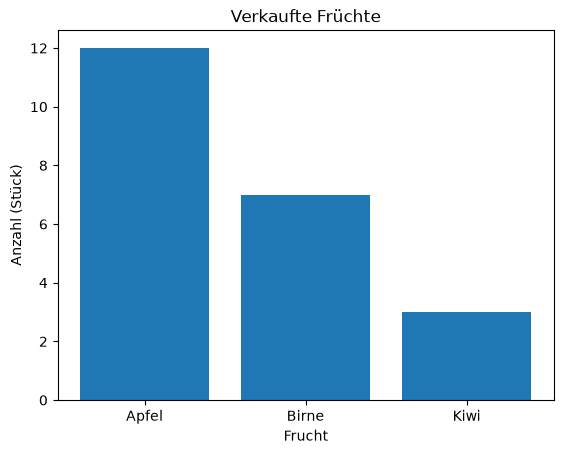

In [31]:
fruits = ["Apfel", "Birne", "Kiwi"]
fruit_counts = [12, 7, 3]

plotter.bar(fruits, fruit_counts)       # Balken: x-Werte, Höhen
plotter.title("Verkaufte Früchte")      # Überschrift
plotter.xlabel("Frucht")                # Beschriftung x-Achse
plotter.ylabel("Anzahl (Stück)")        # Beschriftung y-Achse
plotter.show()                          # anzeigen

### Filme pro Kategorie (Balken)

`barh` zeichnet horizontale Balken, damit die Kategorienamen Platz haben. Die **erste** Zeile landet **unten**. Deshalb sortiert die Abfrage aufsteigend, und die größte Kategorie steht oben.

In [32]:
def get_film_count_per_category():
    """Anzahl der Filme pro Kategorie, aufsteigend sortiert (Spalten: amount, category)."""
    query = sqlalchemy.text("""
        SELECT
            count(film.film_id) AS amount,
            category.name AS category
        FROM film
        JOIN film_category ON film_category.film_id = film.film_id
        JOIN category ON category.category_id = film_category.category_id
        GROUP BY category
        ORDER BY amount
    """)
    return pandas.read_sql(query, pagila)

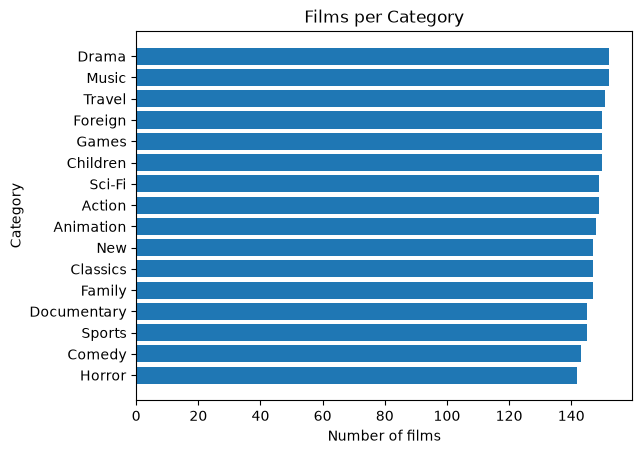

In [33]:
film_counts = get_film_count_per_category()

plotter.barh(film_counts["category"], film_counts["amount"])
plotter.title("Films per Category")
plotter.xlabel("Number of films")
plotter.ylabel("Category")
plotter.show()

### Umsatz pro Monat (Linie)

Monate sind eine Zeitreihe, dafür passt ein Liniendiagramm. Die Zeit liegt auf der x-Achse.

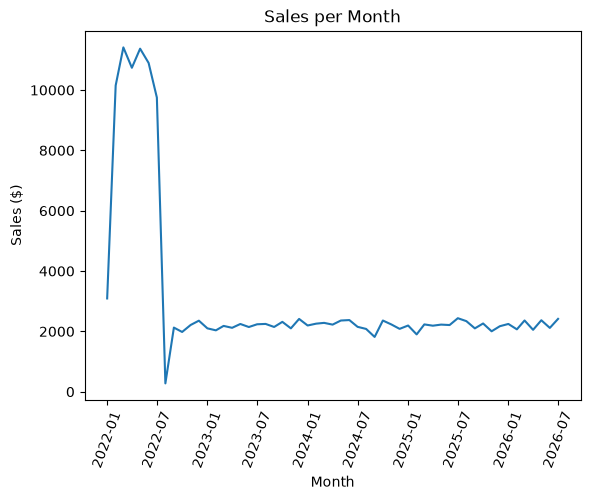

In [34]:
monthly_sales = get_sales_per_month()

plotter.plot(monthly_sales["month"], monthly_sales["sales"])
plotter.title("Sales per Month")
plotter.xlabel("Month")
plotter.ylabel("Sales ($)")
plotter.xticks(rotation=70)
plotter.show()

### Top-10-Kunden (Balken)

Hier darf die Abfrage **nicht** aufsteigend sortieren, sonst liefert `LIMIT 10` die zehn Kunden mit den *wenigsten* Ausleihen. Die Reihenfolge wird deshalb erst nach dem Laden mit `sort_values` umgedreht.

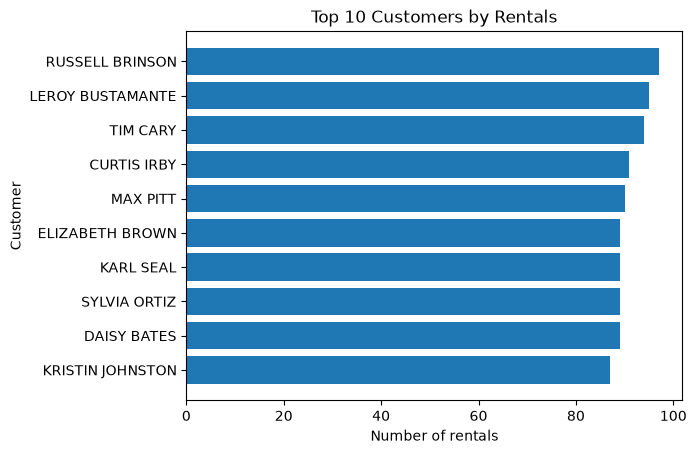

In [35]:
top_customers = get_top_customers_by_rentals(10).sort_values("lends")
customer_names = top_customers["name"] + " " + top_customers["surname"]

plotter.barh(customer_names, top_customers["lends"])
plotter.title("Top 10 Customers by Rentals")
plotter.xlabel("Number of rentals")
plotter.ylabel("Customer")
plotter.show()

## Phase 6 – Daten schreiben und Transaktionen

**Ziel:** Daten aus Python in die Datenbank bringen, ohne Schaden anzurichten.

- Alle eigenen Tabellen liegen im **eigenen Schema `own`**, Pagila-Tabellen bleiben unverändert. Dafür braucht der Nutzer einmalig das Recht `GRANT CREATE ON DATABASE pagila TO accsess_pagila;` (als `postgres` vergeben).
- `IF NOT EXISTS` / `IF EXISTS` machen die Zellen beliebig oft ausführbar (wichtig für Restart & Run All).
- `pagila.begin()` öffnet eine **Transaktion**: am Ende automatisch `commit`, bei einem Fehler automatisch `rollback`. `pagila.connect()` speichert dagegen nichts.
- Mehrere Zeilen auf einmal: `execute` mit einer **Liste von Dictionaries** (executemany). `DataFrame.to_dict("records")` liefert genau dieses Format.
- Datentypen beim Anlegen: `integer`, `text`, `date`, `numeric(10, 2)` (Geldbeträge mit 2 Nachkommastellen). `PRIMARY KEY` verbietet doppelte Werte.

### Übungstabelle `own.praktice` anlegen und füllen

In [36]:
def create_practice_table():
    """
    Legt das Schema own und die Tabelle own.praktice (month, amount) neu an.

    Eine bestehende Tabelle wird vorher gelöscht, damit die Übung immer mit
    einer leeren Tabelle startet.
    """
    create_schema = sqlalchemy.text("CREATE SCHEMA IF NOT EXISTS own")
    drop_table = sqlalchemy.text("DROP TABLE IF EXISTS own.praktice")
    create_table = sqlalchemy.text("""
        CREATE TABLE own.praktice (
            month  date PRIMARY KEY,
            amount numeric(10, 2)
        )
    """)
    with pagila.begin() as connection:
        connection.execute(create_schema)
        connection.execute(drop_table)
        connection.execute(create_table)

In [37]:
create_practice_table()

monthly_sales_records = get_sales_per_month().to_dict("records")
insert_month = sqlalchemy.text("""
    INSERT INTO own.praktice (month, amount)
    VALUES (:month, :sales)
""")

with pagila.begin() as connection:
    connection.execute(insert_month, monthly_sales_records)

In [38]:
%%sql
SELECT count(*) FROM own.praktice

count
55


### Rollback beweisen

Zwei **getrennte** `INSERT`-Befehle in **einer** Transaktion:

1. ein neuer Monat (2030-01-01): klappt für sich
2. ein bereits vorhandener Monat (2024-01-01): verletzt den `PRIMARY KEY`

Der Fehler wird mit `try`/`except` abgefangen. Danach muss die Tabelle unverändert sein (weiterhin 55 Zeilen, kein 2030-01-01), obwohl der erste Befehl erfolgreich war: Das `rollback` hat ihn zurückgenommen.

Warum zwei Befehle? Ein einzelner SQL-Befehl ist in PostgreSQL ohnehin „ganz oder gar nicht“. Erst bei mehreren Befehlen zeigt sich der Nutzen der Transaktion.

In [39]:
insert_new_month = sqlalchemy.text("""
    INSERT INTO own.praktice (month, amount)
    VALUES ('2030-01-01', 10000)
""")
insert_existing_month = sqlalchemy.text("""
    INSERT INTO own.praktice (month, amount)
    VALUES ('2024-01-01', 500)
""")

try:
    with pagila.begin() as connection:
        connection.execute(insert_new_month)
        connection.execute(insert_existing_month)
except sqlalchemy.exc.IntegrityError:
    print("An Error Occured")

An Error Occured


In [40]:
%%sql
SELECT count(*) FROM own.praktice

count
55


### Ergebnis Phase 6

Nach dem absichtlichen Fehler enthält `own.praktice` weiterhin 55 Zeilen, der Monat 2030-01-01 fehlt. Das Rollback hat funktioniert.

## Phase 7 – CSV laden und bereinigen

**Ziel:** Eine fremde, unsaubere Datei sauber in die Datenbank bringen.

Ablauf: **Lesen → Untersuchen → Bereinigen → Prüfen → Laden → Nachprüfen**

Die Datei `film_ratings.csv` (Filmbewertungen von Kunden) wurde von der KI mit absichtlichen Fehlern erstellt.

### Einlesen und untersuchen

In [41]:
ratings_raw = pandas.read_csv("film_ratings.csv")

print("Info")
ratings_raw.info()
print("isna")
print(ratings_raw.isna().sum())
print("duplicated")
print(ratings_raw.duplicated().sum())
print("raw")
print(ratings_raw)

Info
<class 'pandas.DataFrame'>
RangeIndex: 43 entries, 0 to 42
Data columns (total 6 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   rating_id       43 non-null     int64  
 1   film_title      43 non-null     str    
 2   customer_email  41 non-null     str    
 3   rating          41 non-null     float64
 4   rating_date     42 non-null     str    
 5   price_paid      42 non-null     str    
dtypes: float64(1), int64(1), str(4)
memory usage: 2.1 KB
isna
rating_id         0
film_title        0
customer_email    2
rating            2
rating_date       1
price_paid        1
dtype: int64
duplicated
2
raw
    rating_id             film_title            customer_email  rating  \
0           1         ACE GOLDFINGER     anna.berg@example.com     4.0   
1           2       ADAPTATION HOLES   jonas.kraus@example.com     5.0   
2           3        AIRPLANE SIERRA      lea.wolf@example.com     3.0   
3           4         ALASKA PHANTO

### Bericht über die CSV-Verunreinigungen

Z. = Index im DataFrame (0-basiert), nicht die Zeile in der CSV-Datei

**rating** (erlaubt: 1 bis 5)
- Z.4 => rating = NaN (leeres Feld)
- Z.7 => rating = 7.0 (über 5)
- Z.13 => rating = 0.0 (unter 1)
- Z.15 => rating = NaN (in der CSV steht `n/a`, pandas wandelt es beim Einlesen um)
- Z.21 => rating = negativ (-1.0)

**rating_date** (Spalte ist `str` statt Datum)
- Z.28 => rating_date = NaN
- Z.3, Z.14, Z.23, Z.36, Z.37 => Format `TT.MM.JJJJ` statt `JJJJ-MM-TT`
- Z.8, Z.31 => Format `JJJJ/MM/TT` statt `JJJJ-MM-TT`

**price_paid** (Spalte ist `str` statt Zahl)
- Z.16 => price_paid = NaN
- Z.5, Z.14, Z.24 => Dezimalkomma statt Punkt (`3,99`)

**film_title**
- Z.10 => Kleinschreibung (`beneath rush`)
- Z.30 => Kleinschreibung und Leerzeichen am Anfang/Ende (`  core suit  `)
- Z.2 => Leerzeichen am Anfang (`  AIRPLANE SIERRA`)
- Z.18 => Leerzeichen am Ende (`CALIFORNIA BIRDS `)

**customer_email**
- Z.6, Z.40 => email = NaN
- Z.9 => Groß-/Kleinschreibung gemischt und Leerzeichen am Anfang/Ende (`  Anna.Berg@Example.com `)
- Z.20 => Großschreibung (`LEA.WOLF@EXAMPLE.COM`)
- Z.35 => Leerzeichen am Ende

**Duplikate** (`rating_id` muss eindeutig sein)
- Z.11 + Z.12 => exaktes Duplikat (rating_id 12)
- Z.25 + Z.26 => exaktes Duplikat (rating_id 25)
- Z.36 + Z.37 => verstecktes Duplikat (rating_id 35): Z.37 hat ein Leerzeichen vor der E-Mail, deshalb erkennt `duplicated()` es erst nach dem Bereinigen der Leerzeichen

### Bereinigen

Gearbeitet wird an einer **Kopie** (`.copy()`), `ratings_raw` bleibt zum Vergleichen unverändert. Jede Bearbeitung wird der Spalte wieder zugewiesen, weil pandas-Methoden das Original nicht verändern.

| Schritt | Spalte | Vorgehen |
|---|---|---|
| 1 | `film_title` | Leerzeichen entfernen, alles groß (wie in Pagila) |
| 2 | `customer_email` | Leerzeichen entfernen, alles klein, fehlende bleiben leer |
| 3 | ganze Zeile | Duplikate entfernen, **erst nach** Schritt 2, sonst bleibt das versteckte Duplikat |
| 4 | `price_paid` | Komma durch Punkt ersetzen, in Zahl umwandeln |
| 5 | `rating_date` | jedes der drei Formate einzeln umwandeln (`errors="coerce"`), Ergebnisse mit `fillna` zusammenführen. `format="mixed"` würde z. B. `01.04.2024` als 4. Januar lesen |
| 6 | `rating` | Werte außerhalb 1–5 leeren (`where` + `between`), Typ `Int64` (Integer mit Lücken) |

**Entscheidung:** Zeilen ohne gültiges Rating bleiben erhalten, da die Daten noch zeigen, wer welchen Film gesehen hat. Daten sind Daten.

In [42]:
ratings_clean = ratings_raw.copy()

# 1. + 2. Text vereinheitlichen
ratings_clean["film_title"] = ratings_clean["film_title"].str.strip().str.upper()
ratings_clean["customer_email"] = ratings_clean["customer_email"].str.strip().str.lower()

# 3. Duplikate entfernen (nach dem Vereinheitlichen)
ratings_clean = ratings_clean.drop_duplicates()
if ratings_clean.duplicated(subset=["rating_id"]).sum() != 0:
    print("Something went wrong cleaning the data")

# 4. Preis: Dezimalkomma -> Punkt -> Zahl
ratings_clean["price_paid"] = ratings_clean["price_paid"].str.replace(",", ".")
ratings_clean["price_paid"] = pandas.to_numeric(ratings_clean["price_paid"])

# 5. Datum: drei Formate einzeln umwandeln und zusammenführen
dates_iso = pandas.to_datetime(ratings_clean["rating_date"], format="%Y-%m-%d", errors="coerce")
dates_german = pandas.to_datetime(ratings_clean["rating_date"], format="%d.%m.%Y", errors="coerce")
dates_slash = pandas.to_datetime(ratings_clean["rating_date"], format="%Y/%m/%d", errors="coerce")
ratings_clean["rating_date"] = dates_iso.fillna(dates_german).fillna(dates_slash)

# 6. Rating: ungültige Werte leeren, Integer mit Lücken
ratings_clean["rating"] = ratings_clean["rating"].where(ratings_clean["rating"].between(1, 5))
ratings_clean["rating"] = ratings_clean["rating"].astype("Int64")

print(ratings_clean)

    rating_id             film_title           customer_email  rating  \
0           1         ACE GOLDFINGER    anna.berg@example.com       4   
1           2       ADAPTATION HOLES  jonas.kraus@example.com       5   
2           3        AIRPLANE SIERRA     lea.wolf@example.com       3   
3           4         ALASKA PHANTOM   max.schulz@example.com       2   
4           5            ANGELS LIFE    sara.koch@example.com    <NA>   
5           6           ARIZONA BANG    tim.vogel@example.com       4   
6           7        BAKED CLEOPATRA                      NaN       5   
7           8       BANGER PINOCCHIO    nina.hahn@example.com    <NA>   
8           9      BEDAZZLED MARRIED   paul.frank@example.com       1   
9          10       BEHAVIOR RUNAWAY    anna.berg@example.com       3   
10         11           BENEATH RUSH  jonas.kraus@example.com       4   
11         12        BIRCH ANTITRUST     lea.wolf@example.com       5   
13         13        BIRDCAGE CASPER   max.schulz@e

### Prüfen vor dem Schreiben

- Ist jede `rating_id` eine ganze Zahl und eindeutig?
- Hat jeder Film einen Titel in Großbuchstaben?

Die Zelle gibt nur dann etwas aus, wenn eine Prüfung fehlschlägt.

In [43]:
seen_rating_ids = []
for rating_id in ratings_clean["rating_id"]:
    if type(rating_id) != int or rating_id in seen_rating_ids:
        print("The id: " + str(rating_id) + " was found multiple times")
    seen_rating_ids.append(rating_id)

for film_title in ratings_clean["film_title"]:
    if type(film_title) != str or film_title.islower() or film_title == "":
        print("The title " + str(film_title) + " is faulty")
        print("Type is false: " + str(not type(film_title) == str))
        print("Title has lower: " + str(film_title.islower()))
        print("Title is empty: " + str(film_title == ""))

### Tabelle anlegen und laden

Fehlende Werte sind in pandas `NaN`, `NaT` oder `<NA>`. Die Datenbank braucht dafür `NULL`, und psycopg erzeugt `NULL` nur aus Pythons `None`. Deshalb werden vor dem Laden alle Lücken durch `None` ersetzt.

In [44]:
%%sql
CREATE SCHEMA IF NOT EXISTS own;
DROP TABLE IF EXISTS own.film_ratings;
CREATE TABLE IF NOT EXISTS own.film_ratings (
    rating_id      integer PRIMARY KEY,
    film_title     text NOT NULL,
    customer_email text,
    rating         integer,
    rating_date    date,
    price_paid     numeric(10, 2)
)

++
||
++
++

In [45]:
ratings_for_db = ratings_clean.astype(object).where(ratings_clean.notna(), None)
rating_records = ratings_for_db.to_dict("records")

insert_rating = sqlalchemy.text("""
    INSERT INTO own.film_ratings (rating_id, film_title, customer_email, rating, rating_date, price_paid)
    VALUES (:rating_id, :film_title, :customer_email, :rating, :rating_date, :price_paid)
""")

with pagila.begin() as connection:
    connection.execute(insert_rating, rating_records)

### Nachprüfen in SQL

Erwartet: 40 Einträge, `NULL`-Werte: 5 Ratings, 2 E-Mails, 1 Datum, 1 Preis. `count(*) FILTER (WHERE ...)` zählt pro Spalte nur die Zeilen, auf die die Bedingung zutrifft.

In [46]:
%%sql
SELECT
    count(*) AS Einträge,
    count(*) FILTER (WHERE rating IS NULL) AS rating_with_null,
    count(*) FILTER (WHERE customer_email IS NULL) AS customer_email_with_null,
    count(*) FILTER (WHERE rating_date IS NULL) AS rating_date_with_null,
    count(*) FILTER (WHERE price_paid IS NULL) AS price_paid_with_null
FROM own.film_ratings

einträge,rating_with_null,customer_email_with_null,rating_date_with_null,price_paid_with_null
40,5,2,1,1


In [47]:
%%sql
SELECT *
FROM own.film_ratings
WHERE rating_id IN (4, 5, 24)

rating_id,film_title,customer_email,rating,rating_date,price_paid
4,ALASKA PHANTOM,max.schulz@example.com,2,2024-03-17,0.99
5,ANGELS LIFE,sara.koch@example.com,None,2024-03-18,2.99
24,CLERKS ANGELS,nina.hahn@example.com,3,2024-03-27,2.99


### Ergebnis Phase 7

Alle Prüfungen stimmen: 40 Einträge, die erwarteten `NULL`-Werte, und die Stichproben zeigen die bereinigten Werte (z. B. `17.03.2024` → `2024-03-17`).

## Phase 08 – Performance

### Aufgabe 1: Große Testtabelle `own.big_sales`

**Warum?**
Pagila ist zu klein, um Unterschiede in der Geschwindigkeit zu sehen. Bei ein paar Tausend Zeilen ist jede Abfrage in Millisekunden fertig, ob mit oder ohne Index. Deshalb wird eine Tabelle mit 2 Millionen Zeilen erzeugt.

**Aufbau der Tabelle**

| Spalte | Typ | Inhalt |
|---|---|---|
| `sale_id` | `integer` (PRIMARY KEY) | laufende Nummer 1 bis 2.000.000 |
| `customer_id` | `integer` | zufällige Kunden-Nummer 1 bis 1.000 |
| `sale_date` | `date` | zufälliges Datum ab 2020-01-01 (ca. 4 Jahre) |
| `amount` | `numeric(10, 2)` | zufälliger Betrag 1,00 bis 100,00 |

Außer dem PRIMARY KEY gibt es **bewusst keinen Index**. Die Tabelle dient in Aufgabe 2 als Vergleich „vorher“.

**Wie die Daten entstehen**

- `generate_series(1, :row_count)` erzeugt in PostgreSQL selbst eine Zeile pro Zahl. Es werden keine Daten aus Python übertragen, deshalb dauert das nur Sekunden.
- `INSERT INTO ... SELECT` fügt das Ergebnis dieser Abfrage direkt in die Tabelle ein.
- `random()` liefert pro Zeile eine Zufallszahl zwischen 0 und 1. Daraus werden Kunden-Nummer, Datum (Startdatum + zufällige Anzahl Tage) und Betrag berechnet.
- `CAST(:start_date AS date)` statt `:start_date::date`: SQLAlchemy würde die Doppelpunkte von `::` sonst mit dem Platzhalter verwechseln.

**Ablauf im Code**

1. **Einstellungen:** Zeilenzahl, Kundenanzahl, Startdatum und Datumsbereich als Konstanten oben im Code, damit sie leicht änderbar sind.
2. **SQL-Befehle:** alle Befehle als `sqlalchemy.text(...)` vorbereitet.
3. **Ausführen:** `DROP`, `CREATE`, `INSERT` und `ANALYZE` laufen in **einer** Transaktion (`pagila.begin()`). Schlägt ein Schritt fehl, bleibt die Datenbank unverändert.
4. **Kontrolle:** Die Zeilen werden gezählt und mit `ROW_COUNT` verglichen.

**Hinweise**

- Durch `DROP TABLE IF EXISTS` kann die Zelle beliebig oft laufen. Jedes Mal entstehen **neue Zufallsdaten**.
- `ANALYZE` aktualisiert die Statistiken, die PostgreSQL für die Planung von Abfragen nutzt. Ohne sie würde der Planer bei einer frisch gefüllten Tabelle mit falschen Annahmen arbeiten, und die Messungen in Aufgabe 2 wären verfälscht.
- `.scalar()` holt den einzelnen Wert aus der ersten Zeile und ersten Spalte, praktisch für `count(*)`.
- Laufzeit: etwa 5 bis 15 Sekunden, je nach Rechner.

In [48]:
# =====================================================================
# Phase 08 – Aufgabe 1: Große Testtabelle own.big_sales erzeugen
# =====================================================================
import time

# --- Einstellungen ----------------------------------------------------
ROW_COUNT = 2_000_000       # Anzahl der zu erzeugenden Zeilen
CUSTOMER_COUNT = 1_000      # Kunden-Nummern von 1 bis CUSTOMER_COUNT
START_DATE = "2020-01-01"   # frühestes mögliches Verkaufsdatum
DAY_RANGE = 1_500           # Datumsbereich in Tagen ab START_DATE

# --- SQL-Befehle ------------------------------------------------------
# Alte Tabelle entfernen, damit die Zelle beliebig oft laufen kann
drop_table = sqlalchemy.text("""
    DROP TABLE IF EXISTS own.big_sales
""")

# Tabelle anlegen – bewusst nur mit PRIMARY KEY, ohne weitere Indizes
create_table = sqlalchemy.text("""
    CREATE TABLE own.big_sales (
        sale_id     integer        PRIMARY KEY,
        customer_id integer        NOT NULL,
        sale_date   date           NOT NULL,
        amount      numeric(10, 2) NOT NULL
    )
""")

# Testdaten erzeugen: generate_series liefert die Zeilen 1 bis :row_count,
# random() sorgt für zufällige Kunden, Daten und Beträge
fill_table = sqlalchemy.text("""
    INSERT INTO own.big_sales (sale_id, customer_id, sale_date, amount)
    SELECT
        n,
        (random() * (:customer_count - 1))::int + 1,
        CAST(:start_date AS date) + (random() * :day_range)::int,
        round((random() * 99 + 1)::numeric, 2)
    FROM generate_series(1, :row_count) AS n
""")

# Statistiken aktualisieren, damit der Query-Planer die neue Tabelle kennt
analyze_table = sqlalchemy.text("""
    ANALYZE own.big_sales
""")

# Kontrollabfrage
count_rows = sqlalchemy.text("""
    SELECT count(*) FROM own.big_sales
""")

# --- Ausführen --------------------------------------------------------
start_time = time.perf_counter()

# Eine Transaktion: Schlägt ein Schritt fehl, wird alles zurückgerollt
with pagila.begin() as connection:
    connection.execute(drop_table)
    connection.execute(create_table)
    connection.execute(fill_table, {
        "row_count": ROW_COUNT,
        "customer_count": CUSTOMER_COUNT,
        "start_date": START_DATE,
        "day_range": DAY_RANGE,
    })
    connection.execute(analyze_table)

duration = time.perf_counter() - start_time

# --- Kontrolle --------------------------------------------------------
# .scalar() holt den einen Wert aus der ersten Zeile und ersten Spalte
with pagila.connect() as connection:
    row_total = connection.execute(count_rows).scalar()

print(f"Tabelle own.big_sales erzeugt in {duration:.1f} Sekunden")
print(f"Anzahl Zeilen: {row_total:,}".replace(",", "."))

if row_total != ROW_COUNT:
    print(f"ACHTUNG: Erwartet waren {ROW_COUNT:,} Zeilen!".replace(",", "."))

Tabelle own.big_sales erzeugt in 14.7 Sekunden
Anzahl Zeilen: 2.000.000


### Aufgabe 2: Messen, Index anlegen, erneut messen

Gemessen wird eine typische „Nadel im Heuhaufen“-Abfrage: alle Verkäufe von Kunde 42 (rund 2.000 von 2 Millionen Zeilen). `customer_id` hat zu diesem Zeitpunkt **keinen** Index.

- `%%timeit -n 5 -r 3`: 3 Durchgänge mit je 5 Ausführungen, Durchschnitt und Schwankung. Mehrere Läufe gleichen den Cache-Effekt des ersten Laufs aus.
- `%%time`: ein einzelner Lauf. Wichtig ist die **Wall time** (unter Windows ist die CPU-Zeit nur in 15,6-ms-Schritten messbar und unbrauchbar).
- `EXPLAIN ANALYZE`: führt die Abfrage aus und zeigt den Plan. Die **Execution Time** ist die reine Zeit in der Datenbank, ohne Übertragung an Python.

#### Vorher: ohne Index

In [49]:
%%timeit -n 5 -r 3
%%sql
EXPLAIN ANALYZE
SELECT * FROM own.big_sales WHERE customer_id = 42

188 ms ± 14 ms per loop (mean ± std. dev. of 3 runs, 5 loops each)


In [50]:
%%time
%%sql
EXPLAIN ANALYZE
SELECT * FROM own.big_sales WHERE customer_id = 42

CPU times: total: 15.6 ms
Wall time: 179 ms


QUERY PLAN
Gather (cost=1000.00..24354.67 rows=1990 width=18) (actual time=0.764..174.808 rows=1991.00 loops=1)
Workers Planned: 2
Workers Launched: 2
Buffers: shared hit=12739
-> Parallel Seq Scan on big_sales (cost=0.00..23155.67 rows=829 width=18) (actual time=0.053..60.143 rows=663.67 loops=3)
Filter: (customer_id = 42)
Rows Removed by Filter: 666003
Buffers: shared hit=12739
Planning Time: 0.139 ms
Execution Time: 175.045 ms


#### Index anlegen

Ein Index ist wie das Stichwortverzeichnis eines Buches: PostgreSQL schlägt nach, wo die gesuchten Werte stehen, statt jede Zeile zu lesen. Danach aktualisiert `ANALYZE` die Statistiken.

In [51]:
%%sql
CREATE INDEX IF NOT EXISTS idx_big_sales_customer_id ON own.big_sales (customer_id)

++
||
++
++

In [52]:
%%sql
ANALYZE own.big_sales

++
||
++
++

#### Nachher: mit Index

Exakt dieselbe Abfrage, damit der Vergleich fair ist.

In [53]:
%%timeit -n 5 -r 3
%%sql
EXPLAIN ANALYZE
SELECT * FROM own.big_sales WHERE customer_id = 42

5.49 ms ± 278 μs per loop (mean ± std. dev. of 3 runs, 5 loops each)


In [54]:
%%time
%%sql
EXPLAIN ANALYZE
SELECT * FROM own.big_sales WHERE customer_id = 42

CPU times: total: 0 ns
Wall time: 6.34 ms


QUERY PLAN
Bitmap Heap Scan on big_sales (cost=23.89..5336.11 rows=1995 width=18) (actual time=0.754..2.586 rows=1991.00 loops=1)
Recheck Cond: (customer_id = 42)
Heap Blocks: exact=1846
Buffers: shared hit=1850
-> Bitmap Index Scan on idx_big_sales_customer_id (cost=0.00..23.39 rows=1995 width=0) (actual time=0.322..0.322 rows=1991.00 loops=1)
Index Cond: (customer_id = 42)
Index Searches: 1
Buffers: shared hit=4
Planning Time: 0.106 ms
Execution Time: 2.707 ms


### Vergleich vorher / nachher

Werte der Messung vom 19.11.2026 (bei jedem Restart & Run All entstehen neue Zufallsdaten, die Größenordnung bleibt gleich):

| | Vorher (ohne Index) | Nachher (mit Index) | Faktor |
|---|---|---|---|
| **Plan** | `Parallel Seq Scan` (3 Prozesse) | `Bitmap Index Scan` + `Bitmap Heap Scan` | |
| **Execution Time** (in der DB) | 194,0 ms | 2,45 ms | ca. 79× schneller |
| **%%timeit** (im Notebook) | 182 ms | 8,21 ms | ca. 22× schneller |
| **Buffers** (gelesene 8-KB-Seiten) | 12.739 | 1.895 | ca. 7× weniger |
| **Rows Removed by Filter** | ca. 2.000.000 | keine | |

**Was sich im Plan geändert hat**

- **Vorher** liest PostgreSQL jede der 2 Millionen Zeilen (`Seq Scan`), weil es nicht wissen kann, wo Kunde 42 steht. Um rund 2.000 Treffer zu finden, werden fast 2 Millionen Zeilen gelesen und verworfen (`Rows Removed by Filter`). `Gather` sammelt die Ergebnisse der parallelen Prozesse ein.
- **Nachher** schlägt PostgreSQL zuerst im Index nach, *in welchen Seiten* Zeilen von Kunde 42 liegen (`Bitmap Index Scan`, nur 5 Seiten). Danach liest es nur genau diese Seiten aus der Tabelle (`Bitmap Heap Scan`), und zwar in der Reihenfolge, in der sie gespeichert sind. Die Bitmap-Variante statt eines einfachen `Index Scan` wählt der Planer, weil rund 2.000 Treffer über die ganze Tabelle verstreut liegen.

**Warum im Notebook „nur“ Faktor 22 ankommt:** JupySQL, Verbindung und Übertragung kosten einen festen Anteil von einigen Millisekunden. Bei 194 ms fällt er kaum auf, bei 2,5 ms ist er der größte Teil. Die Wirkung des Index zeigt deshalb die **Execution Time** am deutlichsten.

## Phase 9 – Vom Notebook zum Modul

**Ziel:** Wiederverwendbaren Code aus dem Notebook herauslösen und mit Tests absichern.

| Datei | Inhalt |
|---|---|
| `database.py` | Engine `pagila` und die Abfragefunktionen `get_sales_per_month`, `get_sales_per_category`, `get_sales_per_category_and_year` (mit Docstrings) |
| `test_database.py` | Tests für `get_sales_per_month` |
| `test_sales_per_category.py` | Tests für `get_sales_per_category` |
| `test_sales_per_category_and_year.py` | Tests für `get_sales_per_category_and_year` |

- Ein Modul kennt die Variablen des Notebooks nicht. Alles, was eine Funktion braucht, muss im Modul selbst stehen oder importiert werden.
- `%autoreload 2` (Phase 0) übernimmt Änderungen an `database.py` ohne Kernel-Neustart.
- Der bisherige Code oben bleibt bewusst als History im Notebook. Neuer Code kommt ins Modul.

In [55]:
print(database.get_sales_per_month())

         month     sales
0   2022-01-01   3091.79
1   2022-02-01  10151.99
2   2022-03-01  11413.88
3   2022-04-01  10738.56
4   2022-05-01  11371.24
5   2022-06-01  10897.49
6   2022-07-01   9751.56
7   2022-08-01    276.19
8   2022-09-01   2125.81
9   2022-10-01   1981.06
10  2022-11-01   2212.64
11  2022-12-01   2355.09
12  2023-01-01   2100.78
13  2023-02-01   2034.96
14  2023-03-01   2181.81
15  2023-04-01   2118.76
16  2023-05-01   2245.45
17  2023-06-01   2144.88
18  2023-07-01   2235.65
19  2023-08-01   2247.45
20  2023-09-01   2146.66
21  2023-10-01   2316.20
22  2023-11-01   2100.76
23  2023-12-01   2412.97
24  2024-01-01   2195.49
25  2024-02-01   2256.30
26  2024-03-01   2282.30
27  2024-04-01   2224.54
28  2024-05-01   2360.18
29  2024-06-01   2375.25
30  2024-07-01   2150.64
31  2024-08-01   2081.65
32  2024-09-01   1815.84
33  2024-10-01   2360.26
34  2024-11-01   2229.39
35  2024-12-01   2083.91
36  2025-01-01   2194.52
37  2025-02-01   1900.47
38  2025-03-01   2231.49


### Tests ausführen

`!` führt einen Befehl der Kommandozeile aus. `!python` würde das erste Python im Windows-Suchpfad starten (ohne pytest). `{sys.executable}` setzt den Pfad zum Python des Kernels ein (die `.venv`), dort ist pytest installiert. pytest findet alle Dateien `test_*.py` und darin alle Funktionen `test_*` selbst.

In [56]:
print(sys.executable)
!{sys.executable} -m pytest -v

C:\Users\FTester\Desktop\Jupyter\.venv\Scripts\python.exe
============================= test session starts =============================
platform win32 -- Python 3.14.10, pytest-9.2.0, pluggy-1.7.0 -- C:\Users\FTester\Desktop\Jupyter\.venv\Scripts\python.exe
cachedir: .pytest_cache
rootdir: C:\Users\FTester\Desktop\Jupyter\Public\SQLxPython
plugins: anyio-4.16.0, platformdirs-4.14.7
collecting ... collected 35 items

test_database.py::test_returns_dataframe PASSED                          [  2%]
test_database.py::test_row_count PASSED                                  [  5%]
test_database.py::test_column_names PASSED                               [  8%]
test_database.py::test_first_month PASSED                                [ 11%]
test_database.py::test_first_sales PASSED                                [ 14%]
test_database.py::test_months_sorted PASSED                              [ 17%]
test_database.py::test_months_unique PASSED                              [ 20%]
test_database.py::

## Phase 10 – Abschlussprojekt: Umsatz nach Filmkategorien

### Fragestellung

> **Welche Filmkategorien bringen den meisten Umsatz, und wie hat sich das über die Zeit entwickelt?**

### Datengrundlage

- Umsatz: Tabelle `payment` (Betrag und Zahlungsdatum), Zeitraum Januar 2022 bis Juli 2026, Gesamtumsatz 170.962,39 $.
- Kategorie: über die Kette `payment → rental → inventory → film_category → category` (vier JOINs).

### Vorgehen

1. Umsatz pro Kategorie insgesamt: `database.get_sales_per_category()`, Balkendiagramm
2. Entwicklung über die Zeit: `database.get_sales_per_category_and_year()`, Liniendiagramm
3. Fazit

Alle Abfragen liegen in `database.py` und sind mit pytest getestet.

### Wichtige Festlegung: Filme mit mehreren Kategorien

In dieser Pagila-Version gehört ein Film im Schnitt zu etwa **2,4 Kategorien**. Der Umsatz eines Films zählt **voll in jeder seiner Kategorien** („Variante A“). Dadurch lassen sich die Kategorien untereinander vergleichen, ihre **Summe ist aber nicht der Gesamtumsatz**: Sie beträgt 405.100,72 $ statt 170.962,39 $. Die Tests prüfen genau diese Regel (jede Zahlung zählt so oft, wie ihr Film Kategorien hat).

### Teil 1: Umsatz pro Kategorie insgesamt

In [57]:
!{sys.executable} -m pytest -v test_sales_per_category.py

============================= test session starts =============================
platform win32 -- Python 3.14.10, pytest-9.2.0, pluggy-1.7.0 -- C:\Users\FTester\Desktop\Jupyter\.venv\Scripts\python.exe
cachedir: .pytest_cache
rootdir: C:\Users\FTester\Desktop\Jupyter\Public\SQLxPython
plugins: anyio-4.16.0, platformdirs-4.14.7
collecting ... collected 12 items

test_sales_per_category.py::test_returns_dataframe PASSED                [  8%]
test_sales_per_category.py::test_row_count PASSED                        [ 16%]
test_sales_per_category.py::test_column_names PASSED                     [ 25%]
test_sales_per_category.py::test_no_missing_values PASSED                [ 33%]
test_sales_per_category.py::test_sorted_ascending PASSED                 [ 41%]
test_sales_per_category.py::test_categories_unique PASSED                [ 50%]
test_sales_per_category.py::test_all_categories_present PASSED           [ 58%]
test_sales_per_category.py::test_amounts_positive PASSED                 [ 6

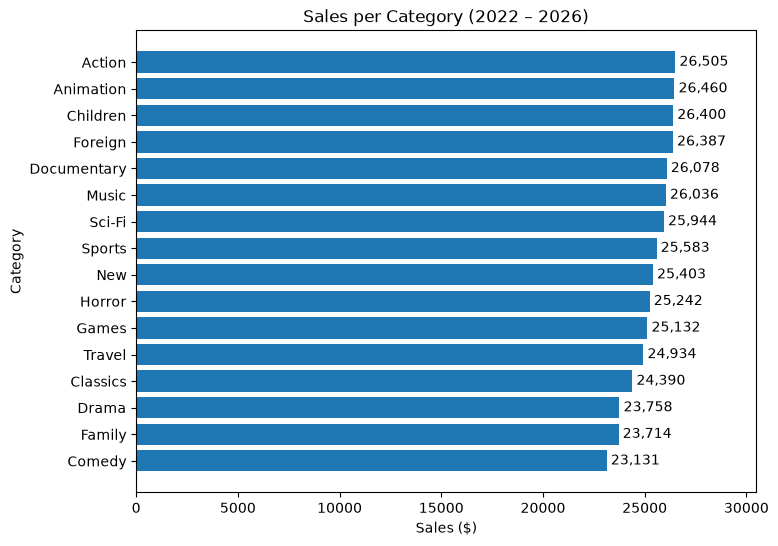

In [58]:
category_sales = database.get_sales_per_category()

plotter.figure(figsize=(8, 6))
category_bars = plotter.barh(category_sales["category"], category_sales["amount"])
plotter.bar_label(category_bars, fmt="{:,.0f}", padding=3)
plotter.xlim(0, category_sales["amount"].max() * 1.15)
plotter.title("Sales per Category (2022 – 2026)")
plotter.xlabel("Sales ($)")
plotter.ylabel("Category")
plotter.show()

**Beobachtung Teil 1**

- Die umsatzstärksten Kategorien sind **Action** (26.505 $), **Animation** (26.460 $), **Children** (26.400 $) und **Foreign** (26.387 $).
- Am schwächsten sind **Comedy** (23.131 $), **Family** (23.714 $) und **Drama** (23.758 $).
- Der Abstand zwischen stärkster und schwächster Kategorie beträgt 3.374 $, also rund **15 %**. Die Kategorien liegen insgesamt nah beieinander, es gibt keine Kategorie, die deutlich heraussticht.

### Teil 2: Entwicklung über die Zeit

Die Abfrage liefert eine Zeile pro Jahr und Kategorie („langes“ Format). `pivot` formt daraus eine Tabelle mit einer Zeile pro Jahr und einer Spalte pro Kategorie. `.plot()` zeichnet dann automatisch eine Linie pro Spalte.

Darstellung: Die Farbpalette `tab20` hat 20 unterscheidbare Farben (die Standardpalette nur 10, dann würden sich Farben wiederholen). Die Legende steht rechts neben dem Diagramm, damit sie keine Linien verdeckt.

In [59]:
!{sys.executable} -m pytest -v test_sales_per_category_and_year.py

============================= test session starts =============================
platform win32 -- Python 3.14.10, pytest-9.2.0, pluggy-1.7.0 -- C:\Users\FTester\Desktop\Jupyter\.venv\Scripts\python.exe
cachedir: .pytest_cache
rootdir: C:\Users\FTester\Desktop\Jupyter\Public\SQLxPython
plugins: anyio-4.16.0, platformdirs-4.14.7
collecting ... collected 12 items

test_sales_per_category_and_year.py::test_returns_dataframe PASSED       [  8%]
test_sales_per_category_and_year.py::test_column_names PASSED            [ 16%]
test_sales_per_category_and_year.py::test_no_missing_values PASSED       [ 25%]
test_sales_per_category_and_year.py::test_year_is_integer PASSED         [ 33%]
test_sales_per_category_and_year.py::test_years_match_payment_table PASSED [ 41%]
test_sales_per_category_and_year.py::test_every_year_has_all_categories PASSED [ 50%]
test_sales_per_category_and_year.py::test_year_category_pairs_unique PASSED [ 58%]
test_sales_per_category_and_year.py::test_row_count PASSED       

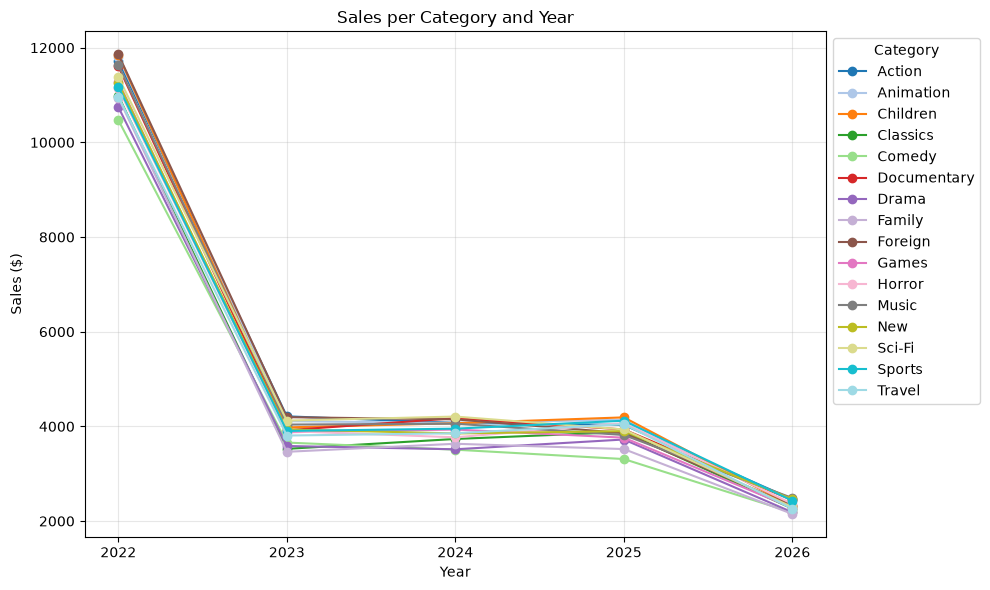

In [60]:
category_sales_per_year = database.get_sales_per_category_and_year()
sales_pivot = category_sales_per_year.pivot(index="year", columns="category", values="amount")

sales_pivot.plot(figsize=(10, 6), colormap="tab20", marker="o")
plotter.title("Sales per Category and Year")
plotter.xlabel("Year")
plotter.ylabel("Sales ($)")
plotter.xticks(sales_pivot.index)
plotter.legend(title="Category", bbox_to_anchor=(1, 1), loc="upper left")
plotter.grid(alpha=0.3)
plotter.tight_layout()
plotter.show()

**Kennzahlen pro Jahr**

- `sum_over_categories`: Summe aller Kategorien im Jahr (mit Mehrfachzählung, siehe Festlegung oben)
- `strongest` / `weakest`: umsatzstärkste und -schwächste Kategorie des Jahres
- `spread_percent`: Abstand zwischen stärkster und schwächster Kategorie in Prozent der schwächsten

In [61]:
yearly_overview = pandas.DataFrame({
    "sum_over_categories": sales_pivot.sum(axis=1).round(2),
    "strongest": sales_pivot.idxmax(axis=1),
    "weakest": sales_pivot.idxmin(axis=1),
    "spread_percent": ((sales_pivot.max(axis=1) - sales_pivot.min(axis=1)) / sales_pivot.min(axis=1) * 100).round(1),
})
yearly_overview

,sum_over_categories,strongest,weakest,spread_percent
year,,,,
2022,180839.55,Foreign,Comedy,13.2
2023,62231.05,Action,Family,21.6
2024,62551.79,Sci-Fi,Comedy,19.9
2025,62240.88,Children,Comedy,26.6
2026,37237.45,Music,Family,15.7


**Rang jeder Kategorie pro Jahr** (1 = höchster Umsatz im Jahr)

In [62]:
category_ranks = sales_pivot.rank(axis=1, ascending=False, method="min").astype(int).T
category_ranks

year,2022,2023,2024,2025,2026
category,,,,,
Action,4,1,4,6,3
Animation,3,4,5,2,7
Children,2,6,6,1,9
Classics,12,15,13,10,12
Comedy,16,13,16,16,15
Documentary,6,8,2,8,4
Drama,15,14,15,14,14
Family,14,16,14,15,16
Foreign,1,2,3,11,8


**Beobachtung Teil 2**

- **Alle 16 Linien verlaufen nahezu parallel.** Der Umsatz hängt vor allem vom **Jahr** ab, nicht von der Kategorie.
- **2022 ist mit Abstand das stärkste Jahr.** Der Grund liegt in den Monatsdaten (Phase 3): Von Februar bis Juli 2022 lag der Umsatz bei rund 10.000 $ pro Monat, ab August 2022 nur noch bei rund 2.000 $ pro Monat.
- **2023 bis 2025 sind gleichmäßig**, ohne erkennbaren Trend einzelner Kategorien.
- **2026 ist kein volles Jahr:** Die Daten enden im Juli 2026. Der niedrigere Wert ist deshalb kein echter Rückgang.
- Wie stabil die Reihenfolge der Kategorien über die Jahre ist, zeigt die Rangtabelle. Die Unterschiede zwischen den Kategorien sind innerhalb eines Jahres klein (siehe `spread_percent`), schon kleine Schwankungen ändern deshalb die Ränge.

### Fazit

**Welche Filmkategorien bringen den meisten Umsatz?**
Über den gesamten Zeitraum liegen **Action, Animation, Children und Foreign** vorn, **Comedy, Family und Drama** hinten. Der Unterschied zwischen der stärksten und der schwächsten Kategorie beträgt aber nur rund 15 %. Keine Kategorie dominiert, das Angebot ist im Umsatz sehr ausgeglichen.

**Wie hat sich das über die Zeit entwickelt?**
Alle Kategorien entwickeln sich nahezu gleich: ein sehr starkes erstes Halbjahr 2022, danach ein deutlich niedrigeres, aber stabiles Niveau von 2023 bis 2025. 2026 ist nur bis Juli enthalten. Die zeitliche Entwicklung betrifft also den gesamten Verleih, nicht einzelne Kategorien.

**Einschränkungen**

- Filme gehören mehreren Kategorien an (im Schnitt etwa 2,4). Ihr Umsatz zählt in jeder Kategorie voll. Die Kategorien sind untereinander vergleichbar, ihre Summe ist nicht der Gesamtumsatz.
- 2026 ist ein Teiljahr und darf nicht direkt mit den vollen Jahren verglichen werden.
- Pagila ist eine Beispieldatenbank. Der sehr gleichmäßige Verlauf ab 2023 spricht dafür, dass diese Daten künstlich erzeugt wurden. Für echte Geschäftsentscheidungen wären die Ergebnisse deshalb nur begrenzt aussagekräftig.